# EECE/CS 7268: Verifiable Machine Learning -- Fall 2025
# HW#2: Formal Verification

**Submission Instructions:** Please upload a .ipynb file (including your code, plots, and written answers) to Gradescope. This file can be updated unlimited times until the submission deadline.

The goal of this assignment is to give you hands-on experience with formal verification of neural networks. You will code some verification algorithms from scratch in the first few problems to build an understanding of how these concepts from class actually play out in code. Then, you will get to use some libraries to gain familiarity with state-of-the-art software in this research field.

You're welcome to use PyTorch, TensorFlow, Keras, or other appropriate libraries to help make your life easier throughout the problems - we tried to make the function signatures somewhat framework-agnostic.

 **Please provide your collaboration statement here or we will assign a zero on this assignment**: I collaborate with Rana. Also, Gil explain how to understand all the problems

In [ ]:
import torch
import numpy as np
import cvxpy as cp
from enum import Enum
import matplotlib.pyplot as plt

For this assignment, we'll use the [NNet](https://github.com/sisl/nnet) format as a language/framework-agnostic description of a ReLU network and its parameters. Here are some possibly useful functions that convert between nnet, numpy arrays, and pytorch models (feel free to use these or not).

In [ ]:
def nnet_to_weights_and_biases(nnet_filename: str) -> tuple[np.ndarray, np.ndarray]:
  # load a nnet text file and extract the weights and biases

  # converted this code from: https://github.com/sisl/NeuralVerification.jl/blob/957cb32081f37de57d84d7f0813f708288b56271/src/utils/util.jl#L10
  with open(nnet_filename, 'r') as f:

    line = f.readline()

    while '//' in line: #skip comments
      line = f.readline()

    # number of layers
    nlayers = int(line.strip().split(',')[0])
    #print(f'{nlayers=}')

    # read in layer sizes
    layer_sizes = [int(x) for x in f.readline().split(',')[1:nlayers+1]]
    #print(f'{layer_sizes=}')

    # read past additonal information
    for i in range(1, 6):
      line = f.readline()

    # i=1 corresponds to the input dimension, so it's ignored
    Ws = []
    bs = []
    for dim in layer_sizes:
      W = np.vstack([[float(x) for x in f.readline().rstrip(',\n ').split(',')] for i in range(dim)])
      b = np.array([float(f.readline().rstrip(',\n ')) for _ in range(dim)])
      #print(f'{W.shape=}', ' ', f'{b.shape=}')
      Ws.append(W)
      bs.append(b)

  return Ws, bs

def weights_and_biases_to_pytorch(Ws: list[np.ndarray], bs: list[np.ndarray]) -> torch.nn.Sequential:
  # given weights and biases, create a torch.nn.Sequential model with relus
  # btwn each linear layer (except no activation on final layer)

  num_layers = len(Ws)

  layers = []
  for W, b in zip(Ws, bs):
    out_features, in_features = W.shape
    layer = torch.nn.Linear(in_features, out_features)
    layer.weight = torch.nn.Parameter(torch.Tensor(W))
    layer.bias = torch.nn.Parameter(torch.Tensor(b))
    layers.append(layer)
    layers.append(torch.nn.ReLU())

  # don't add ReLU to end of NN
  model = torch.nn.Sequential(*layers[:-1])
  return model

def nnet_to_pytorch(nnet_filename: str) -> torch.nn.Sequential:
  # directly convert from nnet text file to pytorch model
  Ws, bs = nnet_to_weights_and_biases(nnet_filename)
  model = weights_and_biases_to_pytorch(Ws, bs)
  #print(f'\n-----nnet_to_pytorch-----\n {model=}')
  return model

def model_to_weights_and_biases(model: torch.nn.Sequential) -> tuple[np.ndarray, np.ndarray]:
  # extract the weights and biases as numpy arrays from a torch.nn.Sequential model
  Ws = []
  bs = []
  for idx, m in enumerate(model.modules()):
    if isinstance(m, torch.nn.Sequential):
      continue
    elif isinstance(m, torch.nn.ReLU):
      continue
    elif isinstance(m, torch.nn.Linear):
      Ws.append(m.weight.data.numpy())
      bs.append(m.bias.data.numpy())
    else:
      print('That layer isn\'t supported.')
      assert 0
  return Ws, bs

In [ ]:
def nominal_and_epsilon_to_range(nominal: np.ndarray, epsilon: np.ndarray | float) -> np.ndarray:
  return np.vstack([nominal-epsilon, nominal+epsilon]).T

def range_to_nominal_and_epsilon(input_range: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
  nominal_input = (input_range[:, 1] + input_range[:, 0]) / 2.
  epsilon = (input_range[:, 1] - input_range[:, 0]) / 2.
  return nominal_input, epsilon

For example, to load a NN controller for a cartpole system, then query the controller for its action at a particular state:

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# adjust the path to where you placed the file
nnet_filename = '/content/drive/MyDrive/cartpole_nnet.nnet'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# A few thing about[ the file format of .nnet](https://github.com/sisl/nnet)

數值範圍與可表達性

線性輸出（不加 ReLU）：**最後輸出可為任意實數（正/負都行）**。
- 適合 logits / Q-values / 力或扭矩等連續量。

加 ReLU：輸出被限制為 ≥ 0。
- 會失去對負值的表達能力（比如想表達「推左 = 負、推右 = 正」的連續控制量就不方便）。

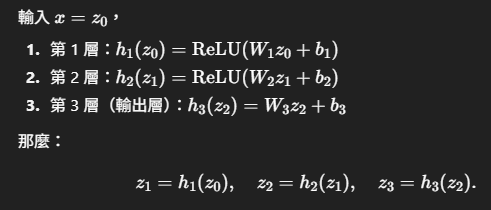

In [ ]:
print('Cartpole Controller')

# Load the NNet file and pass a nominal input to get the class logits
# nnet_filename = '/content/drive/MyDrive/cartpole_nnet.nnet'
nominal_input = torch.Tensor([[0., 0.1, 0.2, 0.3]]) # these 4 values correspond to the 4 states in cartpole
# cart position/ cart velocity/ pole angle/ pole angular velocity
model = nnet_to_pytorch(nnet_filename)
Ws, bs = model_to_weights_and_biases(model)
nominal_output = model(nominal_input)
# in 4-> 16-> 16-> 16-> 2(no Relu)
print(f'\n{nominal_input=}')
print(f'{nominal_output=}')

# Also set up an example set of possible inputs to this NN
#epsilon = 0.1 # epsilon can be a scalar or a vec w/ same shape as nominal_input
#input_range = nominal_and_epsilon_to_range(nominal_input, epsilon)
#print(f'{input_range=}')

Cartpole Controller

-----nnet_to_pytorch-----
 model=Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=2, bias=True)
)

nominal_input=tensor([[0.0000, 0.1000, 0.2000, 0.3000]])
nominal_output=tensor([[12.9007, -1.4208]], grad_fn=<AddmmBackward0>)


2 outputs: 12.9007 and -1.4208
- These are the network’s logits / scores (in the Cartpole setting, they correspond to two possible actions;
- **in HW we treat it like a classifier**

# Problem 1: Sampling-Based Under-Approximations

One way to approximate the set of possible NN outputs for a given set of possible NN inputs is by exhaustively sampling. Here, you will **implement a simple sampling-based method for estimating the min and max values for each dimension of the NN output**. This sampling-based strategy **provides an under-approximation of the output set** (and the corresponding rectangular bound is an under-approximation of the axis-aligned bounding box around the true output set).

The **cartpole NN only has 4 inputs and 2 outputs**, so you can visualize its output samples easily.

**Deliverables**:

- Implement the `output_range_sampling` function
- For the cartpole NN, plot your output samples and the corresponding rectangular bounds for a few different values of `num_samples`

NumPy 取樣 → Torch 前向 → NumPy 聚合

### 1.1) Implement the `output_range_sampling` function

In [ ]:
def output_range_sampling(nnet_filename: str, in_range: np.ndarray, num_samples: int, return_flag = False):

  model = nnet_to_pytorch(nnet_filename) # load model
  model.eval() # set the model to evaluation mode

  #print(f'{in_range.shape=}')
  lower_bound = in_range[:, 0] # lower bound
  upper_bound = in_range[:, 1] # upper bound
  #print(f'{lower_bound.shape=}')
  #print(f'{upper_bound.shape=}\n')
  np.random.seed(0)
  lintf = np.random.uniform(low=lower_bound, high=upper_bound, size=(num_samples, lower_bound.shape[0]))# linear transform to [lower_bound, upper_bound] box
  #print(f'{lintf[:10]=}')
  #print(f'{lintf.shape=}\n')
  lintf_t = torch.tensor(lintf, dtype=torch.float32)
  #print(f'{lintf_t.shape=}\n')

  with torch.no_grad():
      out_t = model(lintf_t).numpy()

  #print(f'{out_t.shape=}')
  #print(f'\n--- output_range_sampling ---\n{out_t[:5]=}\n')

  min_max = np.stack([out_t.min(axis = 0), out_t.max(axis = 0)], axis=1)
  print(f'\n--- output_range_sampling ---\n{min_max=}\n')
  #print(f'{min_max.shape=}')

  # #print(f'{out_t.shape=}')
  # #print(f'\n--- output_range_sampling ---\n{out_t[:5]=}\n')
  # min_max = []
  # print(f'{out_t.min(axis = 0)=}', '\n', f'{out_t.max(axis = 0)=}')
  # min_max.append(out_t.min(axis = 0))
  # min_max.append(out_t.max(axis = 0))

  if return_flag:
    return min_max, lintf, out_t
  return min_max

epsilon = 0.1 # epsilon can be a scalar or a vec w/ same shape as nominal_input
input_range = nominal_and_epsilon_to_range(nominal_input, epsilon)
print(f'{epsilon=}', f'{input_range=}')
num_samples = int(10000)
output_range_sampling(nnet_filename, input_range, num_samples)

epsilon=0.1 input_range=array([[-0.1       ,  0.1       ],
       [ 0.        ,  0.2       ],
       [ 0.1       ,  0.3       ],
       [ 0.20000002,  0.4       ]], dtype=float32)

-----nnet_to_pytorch-----
 model=Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=2, bias=True)
)

--- output_range_sampling ---
min_max=array([[11.31133  , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)



array([[11.31133  , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)

### 1.2) PLOT

In [ ]:
def plot_samples(nnet_filename, in_range, sample_list):
  model = nnet_to_pytorch(nnet_filename)
  model.eval()

  for n in sample_list:
    min_max, lintf, out_t = output_range_sampling(nnet_filename, in_range, n, True)
    print(f'\nN = {n} \nbounds = {min_max}')

    plt.figure(figsize = (7, 7))
    plt.scatter(out_t[:, 0], out_t[:, 1], s = 1, alpha = 0.3)
    x0,x1 = min_max[0,0], min_max[0,1]
    y0,y1 = min_max[1,0], min_max[1,1]
    plt.plot([x0, x1, x1, x0, x0], [y0, y0, y1, y1, y0], color = 'green')
    plt.title(f'(N = {n} ) output samples & rectangle')
    plt.xlabel('Dim 0(x)')
    plt.ylabel('Dim 1(y)')
    plt.show()

epsilon=0.1 input_range=array([[-0.1       ,  0.1       ],
       [ 0.        ,  0.2       ],
       [ 0.1       ,  0.3       ],
       [ 0.20000002,  0.4       ]], dtype=float32)

-----nnet_to_pytorch-----
 model=Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=2, bias=True)
)

-----nnet_to_pytorch-----
 model=Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=2, bias=True)
)

--- output_range_sampling ---
min_max=array([[11.541282 , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)


N = 1000 
bounds = [[11.541282  16.04846  ]
 [-3.9372277 

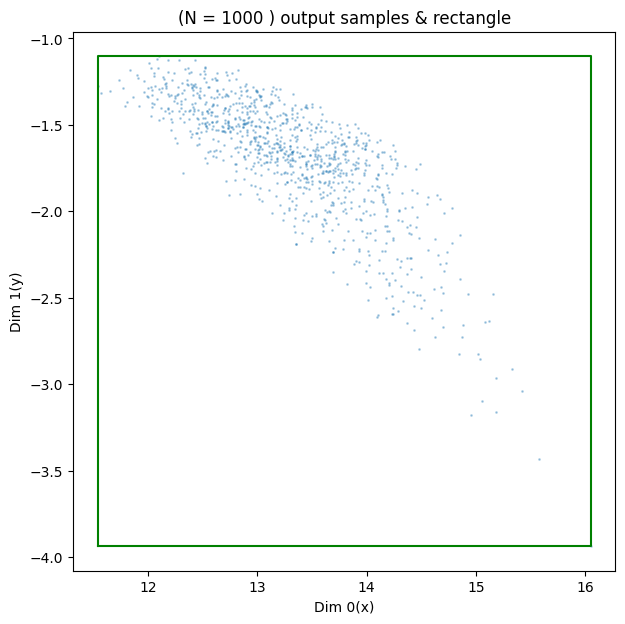


-----nnet_to_pytorch-----
 model=Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=2, bias=True)
)

--- output_range_sampling ---
min_max=array([[11.363704 , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)


N = 5000 
bounds = [[11.363704  16.04846  ]
 [-3.9372277 -1.1029317]]


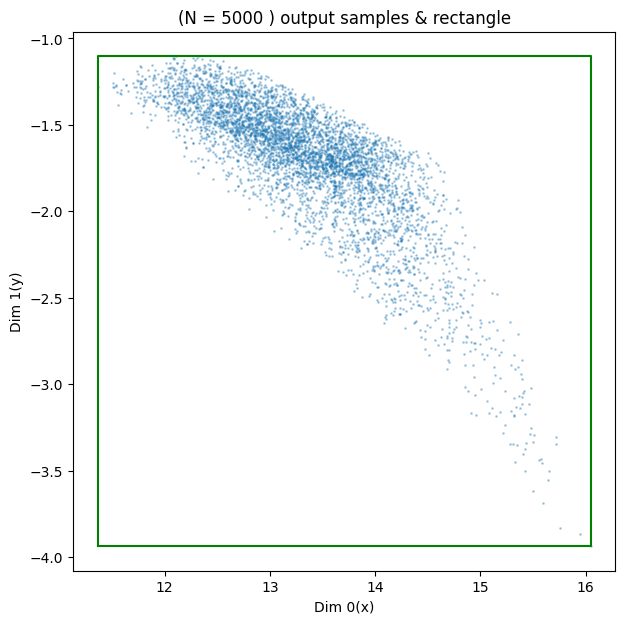


-----nnet_to_pytorch-----
 model=Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=2, bias=True)
)

--- output_range_sampling ---
min_max=array([[11.31133  , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)


N = 10000 
bounds = [[11.31133   16.04846  ]
 [-3.9372277 -1.1029317]]


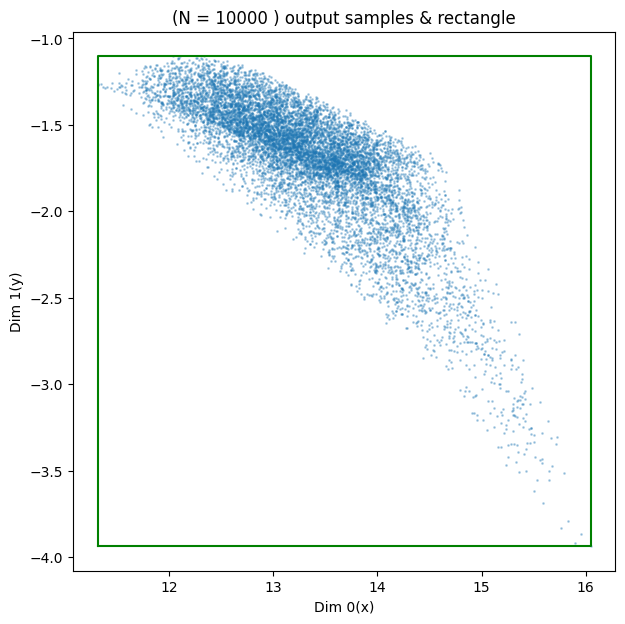


-----nnet_to_pytorch-----
 model=Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=2, bias=True)
)

--- output_range_sampling ---
min_max=array([[11.303885 , 16.183311 ],
       [-4.056096 , -1.0913188]], dtype=float32)


N = 50000 
bounds = [[11.303885  16.183311 ]
 [-4.056096  -1.0913188]]


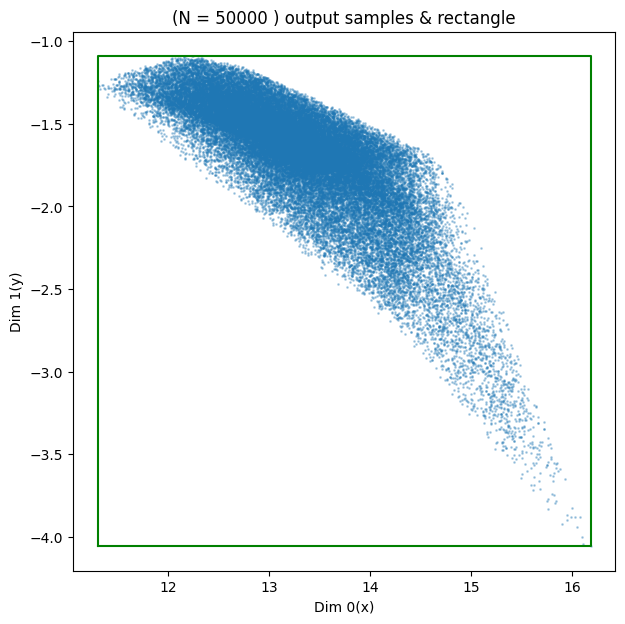


-----nnet_to_pytorch-----
 model=Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=2, bias=True)
)

--- output_range_sampling ---
min_max=array([[11.265327 , 16.183311 ],
       [-4.056096 , -1.0913188]], dtype=float32)


N = 100000 
bounds = [[11.265327  16.183311 ]
 [-4.056096  -1.0913188]]


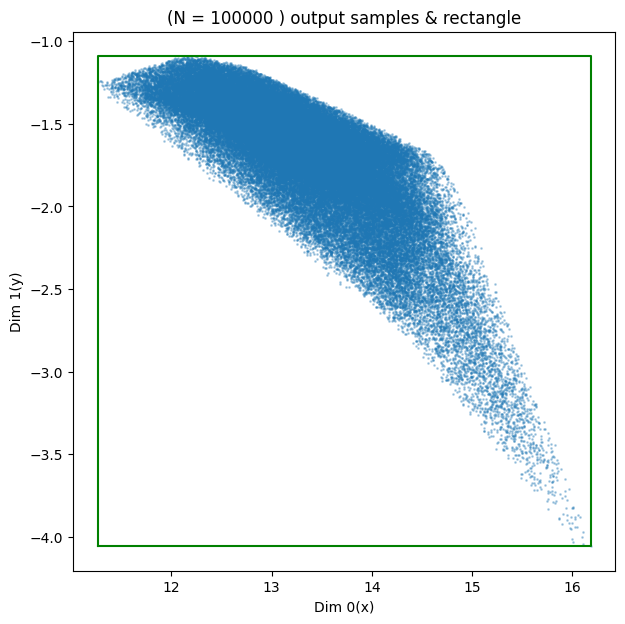

In [ ]:
epsilon = 0.1
input_range = nominal_and_epsilon_to_range(nominal_input, epsilon)
print(f'{epsilon=}', f'{input_range=}')
plot_samples(nnet_filename,input_range,[1000, 5000, 10000, 50000, 100000])

# Problem 2: Interval Bound Propagation (IBP)

Now, you will implement the IBP algorithm to get *outer* bounds on the output set -- which are much more useful for proving that the NN will not produce undesired outputs. You may want to read [the IBP paper](https://arxiv.org/pdf/1810.12715.pdf) (especially around Eqn 6) to help with this.

**Deliverables:**

- Implement the `verify_ibp` function
- Print the `output_range` from your IBP implementation
- Plot your IBP rectangular bounds along with the samples from above to see how ridiculously loose IBP bounds can be

the IBP paper:
$z_k​=Wz_{k−1}​ + \ b$

### A few about paper [IBP](https://chatgpt.com/s/t_68dea78070ec81918464607b54bff162)

In [ ]:
def verify_ibp(nnet_filename: str, in_range: np.ndarray):

  Ws, bs = nnet_to_weights_and_biases(nnet_filename)
  print('\n\n--- verify_ibp ---')
  #print(f'{in_range.shape=}')
  #print(f'{in_range=}')
  # bounding box
  z_lowbar_kprev = in_range[:, 0] # lowbar z0 = x0 - ϵ1
  z_upbar_kprev = in_range[:, 1] # upbar z0 = x0 + ϵ1
  #print('z0=', f'{z_lowbar_kprev.shape=}', f'{z_upbar_kprev.shape=}')

  #print('\n==== start loop ===')
  #print(f'{len(Ws)=}')
  for i in range(len(Ws) - 1):         # without the last layer
    #print(' ----', {i}, '---')
    W, b = Ws[i], bs[i]
    #print(f'{W.shape=}', f'{b.shape=}')

    mu_kprev = ( z_upbar_kprev + z_lowbar_kprev )/ 2  # center
    r_kprev = ( z_upbar_kprev - z_lowbar_kprev )/ 2  # radius
    #print(f'{mu_kprev.shape=}', f'{r_kprev.shape=}')
    #print(f'{mu_kprev=}\n', f'{r_kprev=}')

    mu_k = W @ mu_kprev + b
    r_k = np.abs(W) @ r_kprev
    #print(f'{mu_k.shape=}', f'{r_k.shape=}')
    #print(f'{mu_k=}\n', f'{r_k=}')
    z_upbar_k = mu_k + r_k
    z_lowbar_k = mu_k - r_k

    z_upbar_kprev = np.maximum(z_upbar_k, 0)
    z_lowbar_kprev = np.maximum(z_lowbar_k, 0)

  #print('\n--- the last layer ---')
  #print(' ----', {i+1}, '---')
  # the last layer
  W_last, b_last = Ws[i+1], bs[i+1]

  mu_kprev = ( z_upbar_kprev + z_lowbar_kprev )/ 2  # center
  r_kprev = ( z_upbar_kprev - z_lowbar_kprev )/ 2  # radius
  #print(f'{mu_kprev.shape=}', f'{r_kprev.shape=}')
  #print(f'{mu_kprev=}\n', f'{r_kprev=}')

  mu_k = W_last @ mu_kprev + b_last
  r_k = np.abs(W_last) @ r_kprev
  #print(f'{mu_k.shape=}', f'{r_k.shape=}')
  #print(f'{mu_k=}\n', f'{r_k=}')
  z_upbar_k = mu_k + r_k
  z_lowbar_k = mu_k - r_k
  print('- ibp bound:')
  print(f'{z_upbar_k= }')
  print(f'{z_lowbar_k= }\n')

  return z_lowbar_k, z_upbar_k

In [ ]:
eps = np.array([0.05, 0.1, 0.2, 0.3])
for i in range(len(eps)):
  input_range = nominal_and_epsilon_to_range(nominal_input, eps[i])
  print(f'{i=}', ' ', f'{input_range=}')
  output_range_ibp = verify_ibp(nnet_filename, input_range)
  #print(f'{output_range_ibp.shape=}')
  print(f'{output_range_ibp=}\n\n')

i=0   input_range=array([[-0.05      ,  0.05      ],
       [ 0.05      ,  0.15      ],
       [ 0.15      ,  0.25      ],
       [ 0.25      ,  0.35000002]], dtype=float32)


--- verify_ibp ---
- ibp bound:
z_upbar_k= array([30.31776224,  9.7058196 ])
z_lowbar_k= array([ -1.05745466, -15.22126055])

output_range_ibp=(array([ -1.05745466, -15.22126055]), array([30.31776224,  9.7058196 ]))


i=1   input_range=array([[-0.1       ,  0.1       ],
       [ 0.        ,  0.2       ],
       [ 0.1       ,  0.3       ],
       [ 0.20000002,  0.4       ]], dtype=float32)


--- verify_ibp ---
- ibp bound:
z_upbar_k= array([52.51911865, 23.75044591])
z_lowbar_k= array([-25.60730514, -32.45794935])

output_range_ibp=(array([-25.60730514, -32.45794935]), array([52.51911865, 23.75044591]))


i=2   input_range=array([[-0.2       ,  0.2       ],
       [-0.1       ,  0.3       ],
       [ 0.        ,  0.4       ],
       [ 0.10000001,  0.5       ]], dtype=float32)


--- verify_ibp ---
- ibp bound:
z_up

## 2.2) PLOT

In [ ]:
def plot_ibp(nnet_filename, in_range, sample_numbers=None):

    # 3) IBP 算輸出上下界
    ibp_low, ibp_up = verify_ibp(nnet_filename, in_range)   # 你在 Problem 2 要寫的函式，回傳 (l, u)

    outs = None
    if sample_numbers is not None and sample_numbers > 0:
        plotIBP_MinMax, _, outs = output_range_sampling(nnet_filename, in_range, sample_numbers, True)

    # 5) 畫圖：樣本 + IBP 矩形
    plt.figure(figsize=(5,5))
    if outs is not None:
        plt.scatter(outs[:,0], outs[:,1], s = 0.5, alpha = 0.2)

    # ibp bound
    plt.plot([ibp_low[0], ibp_up[0], ibp_up[0], ibp_low[0], ibp_low[0]],
             [ibp_low[1], ibp_low[1], ibp_up[1], ibp_up[1], ibp_low[1]],
             color = 'blue')
    # sample bound
    plt.plot([plotIBP_MinMax[0,0], plotIBP_MinMax[0,1], plotIBP_MinMax[0,1], plotIBP_MinMax[0,0], plotIBP_MinMax[0,0]],
             [plotIBP_MinMax[1,0], plotIBP_MinMax[1,0], plotIBP_MinMax[1,1], plotIBP_MinMax[1,1], plotIBP_MinMax[1,0]],
             color = 'green', linewidth = 1)
    plt.title('IBP output bounds' + (' + samples' if outs is not None else ''))
    plt.xlabel('logits'); plt.ylabel('Dim 1 (y)')
    plt.grid(True)
    plt.show()




--- verify_ibp ---
- ibp bound:
z_upbar_k= array([194.40266868, 114.85826718])
z_lowbar_k= array([-203.76416136, -149.37982995])



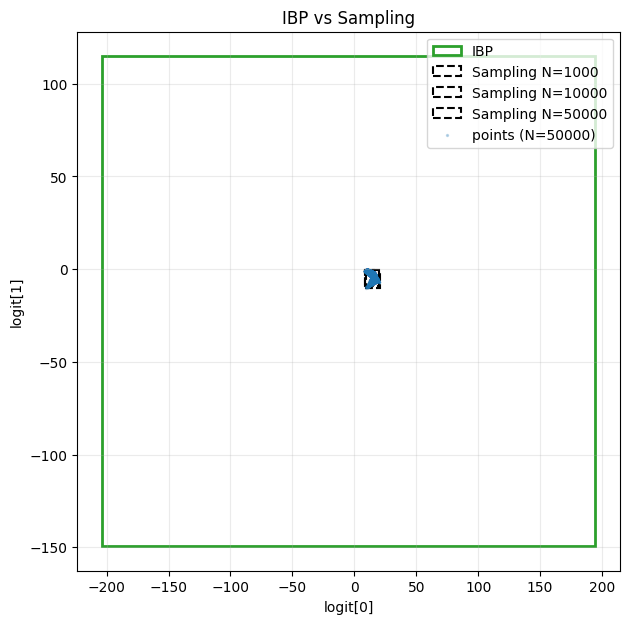

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def plot_ibp_vs_sampling(nnet_filename, in_range, sample_ns=(10_000,), show_points=False, seed=0):
    """
    在同一張圖上畫：
      - IBP 的方框（實線）
      - 多個 sample 數的方框（虛線）
      - （可選）點雲（只畫最大 N 的點，以免太慢）
    """
    # 讀模型一次即可
    model = nnet_to_pytorch(nnet_filename).eval()

    # --- IBP ---
    l_ibp, u_ibp = verify_ibp(nnet_filename, in_range)  # (out_dim,), (out_dim,)
    assert len(l_ibp) == 2, "此繪圖假設輸出 2 維。"

    # --- 繪圖底圖 ---
    fig, ax = plt.subplots(figsize=(7,7))
    # IBP 矩形
    ax.add_patch(Rectangle((float(l_ibp[0]), float(l_ibp[1])),
                           float(u_ibp[0]-l_ibp[0]), float(u_ibp[1]-l_ibp[1]),
                           fill=False, linewidth=2, color='tab:green', label='IBP'))

    # --- Sampling（可多個 N） ---
    sample_ns = sorted(sample_ns)
    lower = in_range[:,0].astype(np.float32)
    upper = in_range[:,1].astype(np.float32)
    d = lower.shape[0]
    rng = np.random.default_rng(seed)

    last_pts = None
    for i, N in enumerate(sample_ns):
        # 產生樣本並前向
        u01 = rng.random((N, d), dtype=np.float32)
        xs = lower + (upper - lower) * u01
        with torch.no_grad():
            ys = model(torch.from_numpy(xs)).cpu().numpy()  # (N, 2)

        l_s = ys.min(axis=0); u_s = ys.max(axis=0)
        # 取樣矩形
        ax.add_patch(Rectangle((float(l_s[0]), float(l_s[1])),
                               float(u_s[0]-l_s[0]), float(u_s[1]-l_s[1]),
                               fill=False, linestyle='--', linewidth=1.5,
                               label=f'Sampling N={N}'))
        # 可選：只畫最大 N 的點雲，避免太擠
        if show_points and (i == len(sample_ns)-1):
            last_pts = ys

    if last_pts is not None:
        ax.scatter(last_pts[:,0], last_pts[:,1], s=2, alpha=0.25, color='tab:blue', label=f'points (N={sample_ns[-1]})')

    ax.set_xlabel("logit[0]"); ax.set_ylabel("logit[1]")
    ax.set_title("IBP vs Sampling")
    ax.grid(True, alpha=0.25); ax.legend()
    plt.show()

# 同一張圖比較 IBP 與多個 sample 數
plot_ibp_vs_sampling(nnet_filename, input_range, sample_ns=(1_000, 10_000, 50_000), show_points=True)


### FIXED sample=1000, change eps



--- verify_ibp ---
- ibp bound:
z_upbar_k= array([30.31776224,  9.7058196 ])
z_lowbar_k= array([ -1.05745466, -15.22126055])


--- output_range_sampling ---
min_max=array([[12.191829 , 14.114109 ],
       [-2.2479858, -1.2509685]], dtype=float32)



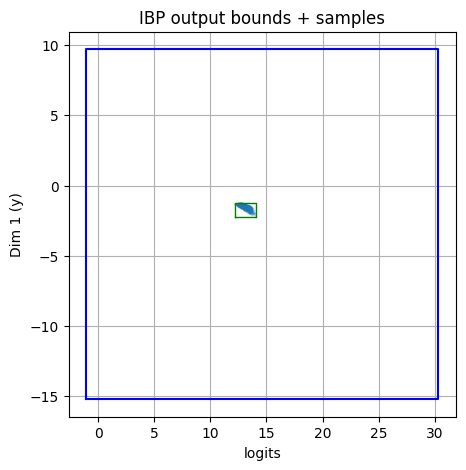

output_range_ibp=(array([-203.76416136, -149.37982995]), array([194.40266868, 114.85826718]))




--- verify_ibp ---
- ibp bound:
z_upbar_k= array([52.51911865, 23.75044591])
z_lowbar_k= array([-25.60730514, -32.45794935])


--- output_range_sampling ---
min_max=array([[11.541282 , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)



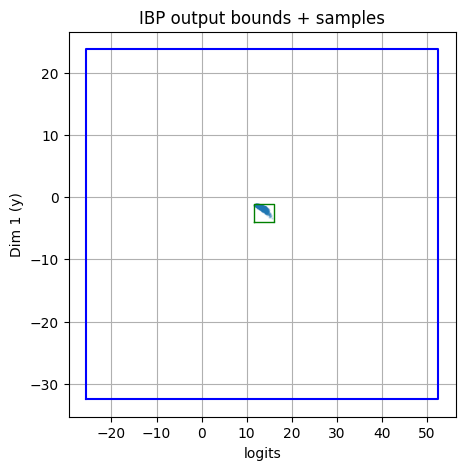

output_range_ibp=(array([-203.76416136, -149.37982995]), array([194.40266868, 114.85826718]))




--- verify_ibp ---
- ibp bound:
z_upbar_k= array([107.45174852,  56.76783614])
z_lowbar_k= array([-81.83013197, -73.95964326])


--- output_range_sampling ---
min_max=array([[10.18309  , 18.110031 ],
       [-7.0023446, -0.866661 ]], dtype=float32)



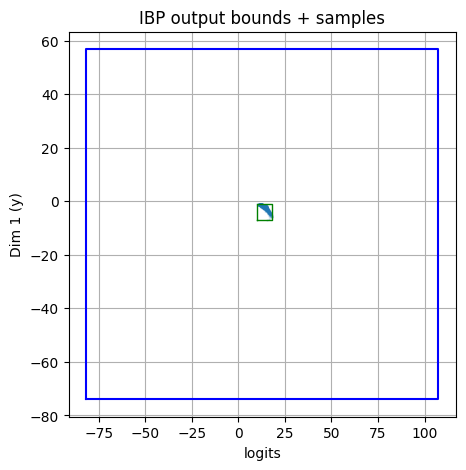

output_range_ibp=(array([-203.76416136, -149.37982995]), array([194.40266868, 114.85826718]))




--- verify_ibp ---
- ibp bound:
z_upbar_k= array([194.40266868, 114.85826718])
z_lowbar_k= array([-203.76416136, -149.37982995])


--- output_range_sampling ---
min_max=array([[ 9.079754 , 19.286404 ],
       [-9.633265 , -0.5524078]], dtype=float32)



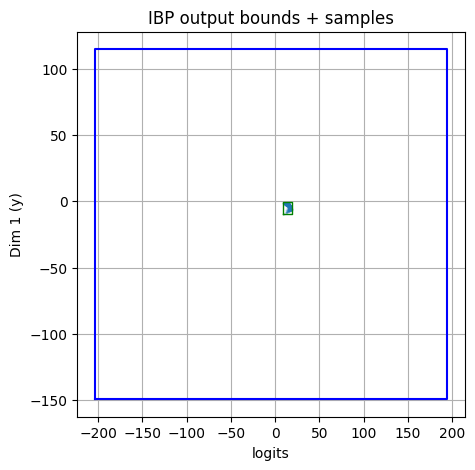

output_range_ibp=(array([-203.76416136, -149.37982995]), array([194.40266868, 114.85826718]))




In [ ]:
eps = np.array([0.05, 0.1, 0.2, 0.3])
for i in range(len(eps)):
  plot_ibp(nnet_filename, nominal_and_epsilon_to_range(nominal_input, eps[i]), 1000)
  #print(f'{output_range_ibp.shape=}')
  print(f'{output_range_ibp=}\n\n')



--- verify_ibp ---
- ibp bound:
z_upbar_k= array([194.40266868, 114.85826718])
z_lowbar_k= array([-203.76416136, -149.37982995])



--- verify_ibp ---
- ibp bound:
z_upbar_k= array([30.31776224,  9.7058196 ])
z_lowbar_k= array([ -1.05745466, -15.22126055])


--- output_range_sampling ---
min_max=array([[12.191829 , 14.114109 ],
       [-2.2479858, -1.2509685]], dtype=float32)



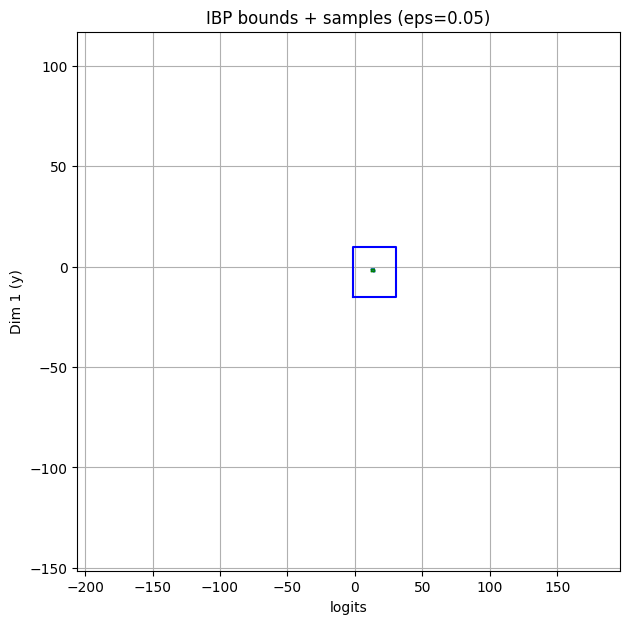



--- verify_ibp ---
- ibp bound:
z_upbar_k= array([52.51911865, 23.75044591])
z_lowbar_k= array([-25.60730514, -32.45794935])


--- output_range_sampling ---
min_max=array([[11.541282 , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)



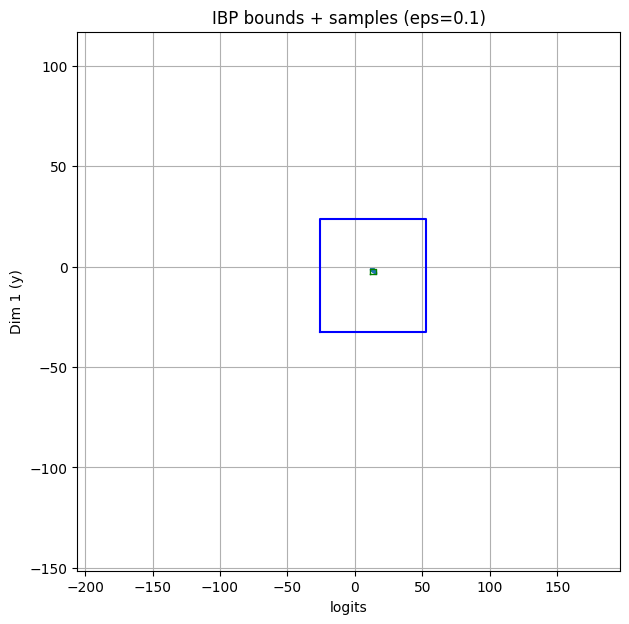



--- verify_ibp ---
- ibp bound:
z_upbar_k= array([107.45174852,  56.76783614])
z_lowbar_k= array([-81.83013197, -73.95964326])


--- output_range_sampling ---
min_max=array([[10.18309  , 18.110031 ],
       [-7.0023446, -0.866661 ]], dtype=float32)



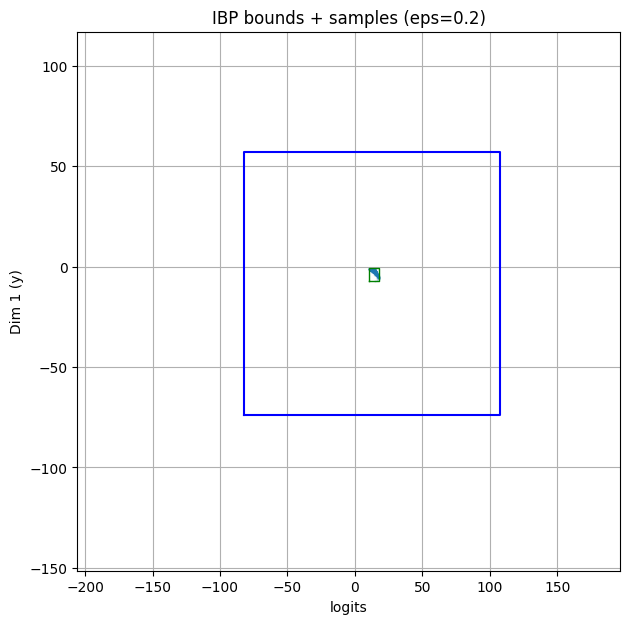



--- verify_ibp ---
- ibp bound:
z_upbar_k= array([194.40266868, 114.85826718])
z_lowbar_k= array([-203.76416136, -149.37982995])


--- output_range_sampling ---
min_max=array([[ 9.079754 , 19.286404 ],
       [-9.633265 , -0.5524078]], dtype=float32)



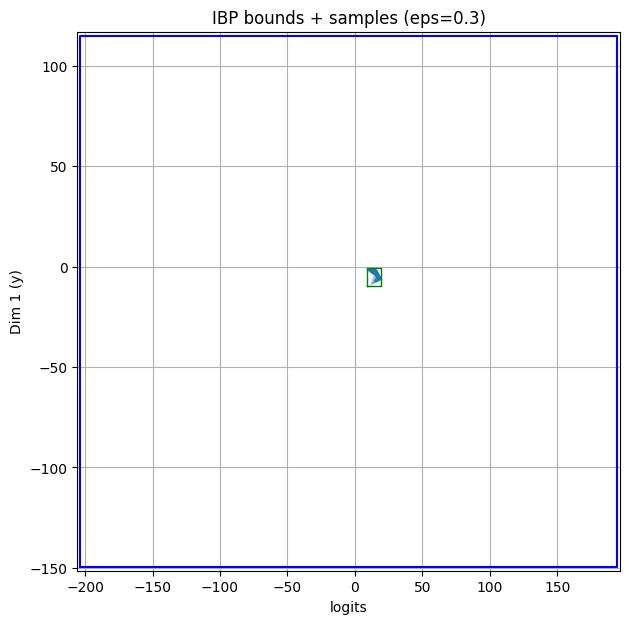

[(0.05,
  np.float64(782.0925464176535),
  np.float32(1.916547),
  np.float64(408.0737756883506)),
 (0.1,
  np.float64(4391.360907899158),
  np.float32(12.774677),
  np.float64(343.7551346944109)),
 (0.2,
  np.float64(24744.343133046314),
  np.float32(48.6372),
  np.float64(508.75345285819105)),
 (0.3,
  np.float64(105210.8455098234),
  np.float32(92.68512),
  np.float64(1135.1427924036543))]

In [ ]:
eps_list = [0.05, 0.1, 0.2, 0.3]
eps_max  = max(eps_list)

# 1) Global axis limits from largest ε
in_range_max = nominal_and_epsilon_to_range(nominal_input, eps_max)
ibp_low_g, ibp_up_g = verify_ibp(nnet_filename, in_range_max)
xlim = (ibp_low_g[0]-2, ibp_up_g[0]+2)
ylim = (ibp_low_g[1]-2, ibp_up_g[1]+2)

# 2) Single loop: plot and compute metrics
rows = []
for eps in eps_list:
    in_range = nominal_and_epsilon_to_range(nominal_input, eps)
    ibp_low, ibp_up = verify_ibp(nnet_filename, in_range)
    samp_minmax, _, outs = output_range_sampling(nnet_filename, in_range, 1000, True)

    # plot
    plt.figure(figsize=(7,7))
    plt.scatter(outs[:,0], outs[:,1], s=0.5, alpha=0.2)
    plt.plot([ibp_low[0], ibp_up[0], ibp_up[0], ibp_low[0], ibp_low[0]],
             [ibp_low[1], ibp_low[1], ibp_up[1], ibp_up[1], ibp_low[1]], color='blue')
    plt.plot([samp_minmax[0,0], samp_minmax[0,1], samp_minmax[0,1], samp_minmax[0,0], samp_minmax[0,0]],
             [samp_minmax[1,0], samp_minmax[1,0], samp_minmax[1,1], samp_minmax[1,1], samp_minmax[1,0]],
             color='green', linewidth=1)
    plt.xlim(xlim); plt.ylim(ylim); plt.grid(True)
    plt.title(f'IBP bounds + samples (eps={eps})')
    plt.xlabel('logits'); plt.ylabel('Dim 1 (y)')
    plt.show()

    # metrics (optional)
    ibp_w = ibp_up[0] - ibp_low[0]; ibp_h = ibp_up[1] - ibp_low[1]
    sm_w  = samp_minmax[0,1] - samp_minmax[0,0]; sm_h  = samp_minmax[1,1] - samp_minmax[1,0]
    ibp_area = max(ibp_w,0)*max(ibp_h,0); sm_area = max(sm_w,0)*max(sm_h,0)
    rows.append((float(eps), ibp_area, sm_area, (ibp_area/sm_area if sm_area>0 else float('inf'))))
rows

### FIXED eps =xxx, change sample=1000

In [ ]:
# set up an example set of possible inputs to this NN
epsilon = 0.1
plot_ibp(nnet_filename, nominal_and_epsilon_to_range(nominal_input, epsilon), 1000)
#print(f'{output_range_ibp.shape=}')
print(f'{output_range_ibp=}')



--- verify_ibp ---
- ibp bound:
z_upbar_k= array([52.51911865, 23.75044591])
z_lowbar_k= array([-25.60730514, -32.45794935])


--- output_range_sampling ---
min_max=array([[11.541282 , 16.04846  ],
       [-3.9372277, -1.1029317]], dtype=float32)



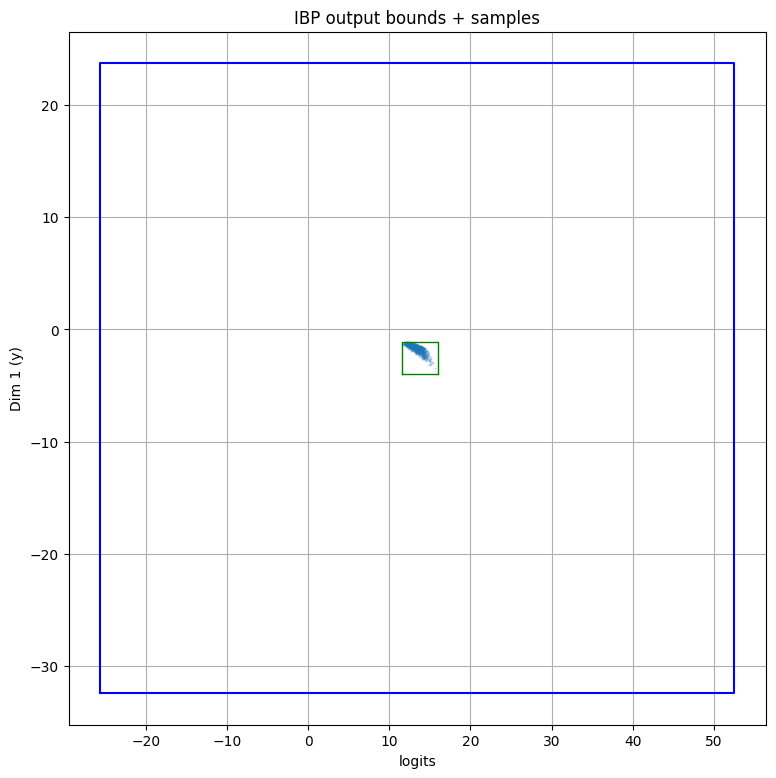

In [ ]:
epsilon = 0.1
plot_ibp(nnet_filename, nominal_and_epsilon_to_range(nominal_input, epsilon), 1000)

# Problem 3: Linear Program (LP)

Since IBP's bounds are usually too loose to say something useful about the NN's output set, you will now implement an LP-based verification algorithm that should provide much tighter bounds while remaining computationally reasonable.

You will set up an LP (e.g., using `cvxpy` to set up variables, constraints, and objectives corresponding to the NN verification problem) for each side of the rectangle (i.e., min & max per output dimension, which can be done by simply changing the objective). To turn the ReLU constraints into linear equality/inequality constraints, you can check which neurons are 'active', 'inactive', or 'uncertain' and add the corresponding relaxed constraints. To know which neurons belong to which category, you will need to acquire intermediate bounds -- there are lots of ways to do this!

In [ ]:
def verify_lp(nnet_filename: str, input_range: np.ndarray) -> np.ndarray:

  # TODO: implement this!

  return output_range

output_range_lp = verify_lp(nnet_filename, input_range)
print(f'{output_range_lp=}')

# Problem 4: Verify Classifier Robustness

So far, you have written verification algorithms that provide upper and lower bounds on each output of the NN. Here, you will slightly modify your LP verifier so that it verifies the *robustness* of a *classifier* (i.e., prove that the classifier predicts the same class for every input within some range).

If the verification algorithm is able to prove robustness, you should return `VerifierResults.Robust`. If the verification algorithm is unable to prove robustness, you should return `VerifierResults.Unsure` (remember that this doesn't necessarily mean the classifier isn't robust, just that our algorithm failed to find a proof). I also added a `VerifierResults.Timeout` option, because you will often see this in real verification algorithms, but you do not need to use this here.

To start, you can pretend the cartpole controller was a classifier and try to see how large of an epsilon you can specify until you can't verify the robustness anymore.

Then, you can load an MNIST classifier (code below) and try to see how large of an epsilon for which you can still verify robustness around a nominal image. Since the MNIST classifier is a way bigger NN, there will be some impact on the runtime of your LP.

**Deliverables:**

- Implement `verify_classification_robustness_lp`
- Plot and/or briefly describe your findings w.r.t. robustness verification as you increase epsilon for the cartpole controller
- Plot and/or briefly describe your findings w.r.t. robustness verification as you increase epsilon for the MNIST classifier

In [ ]:
class VerifierResults(Enum):
  Robust = 0
  Unsure = 1
  Timeout = 2

def verify_classification_robustness_lp(nnet_filename: str, input_range: np.ndarray) -> int:

  # TODO: implement this!

  return VerifierResults.Robust

verifier_result = verify_classification_robustness_lp(nnet_filename, input_range)

Load a NN classifier for MNIST, then query the model at a particular image:

In [ ]:
print('MNIST Classifier')

# Load the NNet file and pass a nominal input to get the class logits
nnet_filename_mnist = '/content/drive/MyDrive/mnist1.nnet'

from tensorflow.keras.datasets import mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()
img_index = 2 # this one should be correctly classified as a 4...
nominal_input_mnist = torch.Tensor(x_train[img_index].flatten())
model_mnist = nnet_to_pytorch(nnet_filename_mnist)
Ws_mnist, bs_mnist = model_to_weights_and_biases(model_mnist)
nominal_output = model_mnist(nominal_input_mnist)
nominal_class = nominal_output.argmax()
print(f'{nominal_output=}')
print(f'Predicted Class: {nominal_class}, True Class: {y_train[img_index]}')

# Also set up an example set of possible inputs to this NN

epsilon_mnist = 2*np.ones((784))
input_range_mnist = nominal_and_epsilon_to_range(nominal_input_mnist, epsilon_mnist)
print(f'{input_range_mnist=}')

In [ ]:
verifier_result = verify_classification_robustness_lp(nnet_filename_mnist, input_range_mnist)

# Problem 5: Explore the `jax_verify` library for verification

There are a few excellent open-source libraries for NN verification. For example, `jax_verify` has implementations of IBP, CROWN, and many other algorithms. These methods can handle a broader class of NNs than just the ReLU NNs you worked with above, so they may be useful tools to leverage in your research or projects.

A big upside of `jax_verify` is that it supports JIT compilation, which can speed up verification algorithms by 10-100x (you don't need to set up JIT compilation for this assignment, but you're encouraged to try that out if you're curious).

Note that the `jax_verify` that is available by default in PyPi is an old version from 2020 that has a slightly different API - installing a more recent version is recommended as we do below.

In [ ]:
# Install my fork of jax_verify, which fixes a few deprecation errors in the mainline repo
!pip install git+https://gitlab.com/neu-autonomy/certifiable-learning/jax_verify@mainline_repo

In [ ]:
import jax.numpy as jnp
import jax_verify
import functools

Some utility methods that help set up the NN in jax:

In [ ]:
def pytorch_model_to_jax(torch_model: torch.nn.Sequential):
  params = []
  act = None

  # Extract params (weights, biases) from torch layers, to be used in
  # jax.
  # Note: This propagator assumes a feed-forward relu NN.
  for m in torch_model.modules():
    if isinstance(m, torch.nn.Sequential):
      continue
    elif isinstance(m, torch.nn.ReLU):
      if act is None or act == 'relu':
        act = 'relu'
    elif isinstance(m, torch.nn.Linear):
      w = m.weight.data.numpy().T
      b = m.bias.data.numpy()
      params.append((w, b))
  return functools.partial(relu_nn, params)

def relu_nn(params, inputs):
  for W, b in params[:-1]:
    outputs = jnp.dot(inputs, W) + b
    inputs = jnp.maximum(outputs, 0)
  W, b = params[-1]
  return jnp.dot(inputs, W) + b

def jax_interval_to_np_range(interval: jax_verify.IntervalBound) -> np.ndarray:
  return np.vstack([interval.lower, interval.upper]).T

def np_range_to_jax_interval(input_range: np.ndarray) -> jax_verify.IntervalBound:
  return jax_verify.IntervalBound(input_range[:, 0], input_range[:, 1])

jax_model = pytorch_model_to_jax(model)

An example of using jax_verify's implementation of IBP on our cartpole control NN

In [ ]:
# Example of a fwd pass on the NN using jax
nominal_output_jax = jax_model(jnp.array(nominal_input))

# Example of computing bounds using IBP as implemented by jax_verify
input_bounds = np_range_to_jax_interval(input_range)
output_bounds_ibp_jax = jax_verify.interval_bound_propagation(
    jax_model, input_bounds)
output_range_ibp_jax = jax_interval_to_np_range(output_bounds_ibp_jax)
print(f'output bounds via IBP (jax_verify): \n{output_range_ibp_jax}')

Does that output match the output of your IBP implementation?

Now for your job: take a look at jax_verify's documentation to see how to use the backward CROWN verifier.

**Deliverables:**

- output bounds using backward CROWN, rather than IBP

# Problem 6: Explore the `auto-LiRPA` library for verification

`auto-LiRPA` is a verification library based on PyTorch and one of the main developers was a Northeastern PhD student (Kaidi Xu)!

Just like with the previous problem, the next cells show you how to install the package and run IBP, then we ask you to look into their documentation and run backward CROWN on the same problem.

**Note:** I suggest doing this part last, because pip may try to downgrade the version of pytorch installed to satisfy requirements. You may also need to restart your kernel after the pip install. If you're on Colab and things seem messed up, you can always do `Runtime > Disconnect and delete runtime` (stronger than restarting the runtime, which doesn't reset to the default set of installed packages).

In [ ]:
!pip install auto-lirpa

An example of using jax_verify's implementation of IBP on our cartpole control NN:

In [ ]:
from auto_LiRPA import BoundedModule, BoundedTensor, PerturbationLpNorm

# Wrap the model with auto_LiRPA.
model = BoundedModule(model, torch.Tensor(nominal_input))
# Define perturbation. Here we add Linf perturbation to input data.
ptb = PerturbationLpNorm(norm=np.inf, eps=torch.Tensor([epsilon]))
# Make the input a BoundedTensor with the pre-defined perturbation.
my_input = BoundedTensor(torch.Tensor(nominal_input), ptb)
# Regular forward propagation using BoundedTensor works as usual.
prediction = model(my_input)
# Compute LiRPA bounds using IBP
lb, ub = model.compute_bounds(x=(my_input,), method='ibp')
output_range_ibp_autolirpa = np.vstack([lb.detach().numpy(), ub.detach().numpy()]).T
print(f'output bounds via IBP (auto-lirpa): \n{output_range_ibp_autolirpa}')

Does that match your implementation of IBP? What about `jax_verify`'s?

Now for your job: compute output bounds using `auto-LiRPA`'s implementation of backward CROWN

**Deliverables:**

- output bounds using backward CROWN, rather than IBP

All done!